In [1]:
import os
import json
import random
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import pickle
import pandas as pd
import torch
import torch.nn.functional as F
import re
import time
from scipy.stats import gaussian_kde
from sklearn.neighbors import KDTree


In [2]:
import os
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'  # Catch errors immediately

import torch
torch.cuda.empty_cache()

In [38]:
from modules_general import (
    SimpleStackedHamiltonianNetwork_general,
    SegmentDataLoader_general,
    train_model_general,
    make_validation_batch,
    load_checkpoint,
    load_segment_progress,
    plot_segment_progress,
    summarise_segment_progress,
    InverseStackedHamiltonianNetwork_general,
    Autoregressive_Handoff_Inference_Protocol_general,
    Batched_Autoregressive_Handoff_Inference_Protocol_general,
    build_omega_general,
    compute_jacobian_functional_general,
    compute_symplectic_product_general,
    test_canonical_transformation_on_trajectory_general,
    prediction_loss_euclidean_general,
    test_model_all_observations_all_trajectories_general,
    make_energy_henon_heiles,
    prediction_loss_general,
    test_model_in_single_trajectory_general,
    test_model_varying_observation_single_trajectory_general,
    plot_varying_observation_results_general,
    
    )

In [42]:
from modules import (    
    get_data_from_trajectory_id,
    visualize_epoch_metrics,
    prediction_loss_euclidean,
    plot_summary_statistics,
    prediction_loss,
    count_parameters,
    )

In [5]:
save_dir_path = "./save_directory_HH_general_1" 


In [6]:


with open("all_dataframes_HH_portable.pkl", "rb") as f:
    portable = pickle.load(f)

loaded_dfs = {}
for name, d in portable.items():
    df = pd.DataFrame(d["data"], columns=d["columns"])
    df.index = pd.Index(d["index_values"], name=d["index_name"])
    loaded_dfs[name] = df

# Verify shapes survived the round trip
print(f"{'name':<20}{'loaded shape':<16}status")
for name, d in portable.items():
    got, exp = loaded_dfs[name].shape, d["shape"]
    status = "OK" if got == exp else f"!! MISMATCH (expected {exp})"
    print(f"{name:<20}{str(got):<16}{status}")

name                loaded shape    status
train_df            (16032, 7)      OK
val_df              (5344, 6)       OK
test_df             (5344, 6)       OK
train_id_df         (48, 11)        OK
val_id_df           (16, 9)         OK
test_id_df          (16, 9)         OK
train_seg_df        (16032, 8)      OK
train_seg_id_df     (288, 14)       OK
val_seg_df          (5344, 7)       OK
val_seg_id_df       (96, 12)        OK


In [7]:
train_df        = loaded_dfs["train_df"]
val_df          = loaded_dfs["val_df"]
test_df         = loaded_dfs["test_df"]

train_id_df     = loaded_dfs["train_id_df"]
val_id_df       = loaded_dfs["val_id_df"]
test_id_df      = loaded_dfs["test_id_df"]

train_seg_df    = loaded_dfs["train_seg_df"]
train_seg_id_df = loaded_dfs["train_seg_id_df"]
val_seg_df      = loaded_dfs["val_seg_df"]
val_seg_id_df   = loaded_dfs["val_seg_id_df"]

In [11]:

SIGMA2_OLD = 0.1
HH_COORDS = ['x', 'y', 'px', 'py']

# ---- paste the two printed lines here (replace the placeholder numbers) ----
OLD_WITHIN_VAR = [
    ('Task1', {'x': 5.705888e-01, 'u': 6.005445e-01}),
    ('Task2', {'x': 6.691010e-01, 'u': 1.702431e+00}),
]

# 1) HH signal variances -----------------------------------------------------
grp = train_seg_df.groupby(['trajectory_id', 'segment_id'])
within = grp[HH_COORDS].var(ddof=0).mean()      # mean within-segment variance
pooled = train_seg_df[HH_COORDS].var(ddof=0)    # variance over all samples

print("=== HH ===")
for c in HH_COORDS:
    print(f"  {c:>2}: within_var={within[c]:.4e}  pooled_var={pooled[c]:.4e}  "
          f"SNR_within@0.1={within[c]/SIGMA2_OLD:6.2f}")

# 2) old validated per-channel SNR band -------------------------------------
old_snr = [v/SIGMA2_OLD for _, d in OLD_WITHIN_VAR for v in d.values()]
SNR_min_old, SNR_max_old = min(old_snr), max(old_snr)
print(f"\nOld validated per-channel SNR band (within): [{SNR_min_old:.2f}, {SNR_max_old:.2f}]")

# 3) worst HH channel -> single-sigma range ---------------------------------
worst_c = min(HH_COORDS, key=lambda c: within[c]); minVar = within[worst_c]
s2_hi = minVar / SNR_min_old     # match old DIRTIEST channel -> largest sigma
s2_lo = minVar / SNR_max_old     # match old CLEANEST channel -> smallest sigma
print(f"\nHH worst channel: '{worst_c}'  within_var={minVar:.4e}")
print(f"SNR-matched sigma^2 in [{s2_lo:.4e}, {s2_hi:.4e}]"
      f"  ->  sigma in [{s2_lo**0.5:.4f}, {s2_hi**0.5:.4f}]")

# 4) chaos diagnostic --------------------------------------------------------
tl = train_seg_df['tau_L'].replace([np.inf, -np.inf], np.nan)
tl = tl[(tl.notna()) & (tl > 0)]
print(f"\ntau_L>0 : count={tl.size}  min={tl.min():.3f}  p1={tl.quantile(.01):.3f}  "
      f"p5={tl.quantile(.05):.3f}  median={tl.median():.3f}")

seg_tauL = grp['tau_L'].apply(lambda s: s[(s > 0) & np.isfinite(s)].min())
seg_span = grp['t'].apply(lambda s: s.max() - s.min())
print(f"\nSegment t-span: min={seg_span.min():.3f}  median={seg_span.median():.3f}  "
      f"max={seg_span.max():.3f}   (CHECK: physical time, same units as tau_L?)")
ratio = (seg_span / seg_tauL).replace([np.inf, -np.inf], np.nan).dropna()
print(f"T_seg/tau_L : median={ratio.median():.2f}  p95={ratio.quantile(.95):.2f}  max={ratio.max():.2f}")

=== HH ===
   x: within_var=5.6416e-02  pooled_var=6.3115e-02  SNR_within@0.1=  0.56
   y: within_var=4.9324e-02  pooled_var=5.4818e-02  SNR_within@0.1=  0.49
  px: within_var=5.0699e-02  pooled_var=5.2567e-02  SNR_within@0.1=  0.51
  py: within_var=4.5160e-02  pooled_var=4.6460e-02  SNR_within@0.1=  0.45

Old validated per-channel SNR band (within): [5.71, 17.02]

HH worst channel: 'py'  within_var=4.5160e-02
SNR-matched sigma^2 in [2.6527e-03, 7.9147e-03]  ->  sigma in [0.0515, 0.0890]

tau_L>0 : count=8604  min=8.563  p1=10.202  p5=12.170  median=20.820

Segment t-span: min=7.057  median=8.408  max=8.559   (CHECK: physical time, same units as tau_L?)
T_seg/tau_L : median=0.50  p95=0.79  max=0.99



📊 Metric summaries:
  Lowest loss of metric 'val_prediction_loss_' recorded in epoch 2111 with the value: 0.0419, the losses of the last 5 epochs are: ['0.0437', '0.0440', '0.0438', '0.0429', '0.0419']
  Lowest loss of metric 'val_prediction_loss_training_set' recorded in epoch 2050 with the value: 0.0329, the losses of the last 5 epochs are: ['0.0351', '0.0341', '0.0344', '0.0338', '0.0331']
  Lowest loss of metric 'train_total_loss_' recorded in epoch 2039 with the value: 0.4716, the losses of the last 5 epochs are: ['0.4756', '0.4749', '0.4746', '0.4759', '0.4728']
  Lowest loss of metric 'train_hsic_loss_' recorded in epoch 625 with the value: 0.0000, the losses of the last 5 epochs are: ['0.0000', '0.0000', '0.0000', '0.0000', '0.0000']
  Lowest loss of metric 'validation_criterio' recorded in epoch 2111 with the value: 0.0419, the losses of the last 5 epochs are: ['0.0437', '0.0440', '0.0438', '0.0429', '0.0419']
  Lowest loss of metric 'mean_grad_norm_' recorded in epoch 1 with

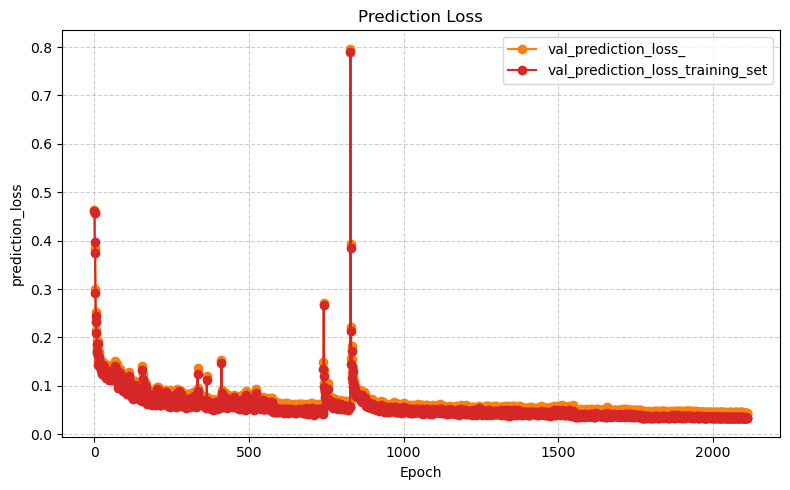

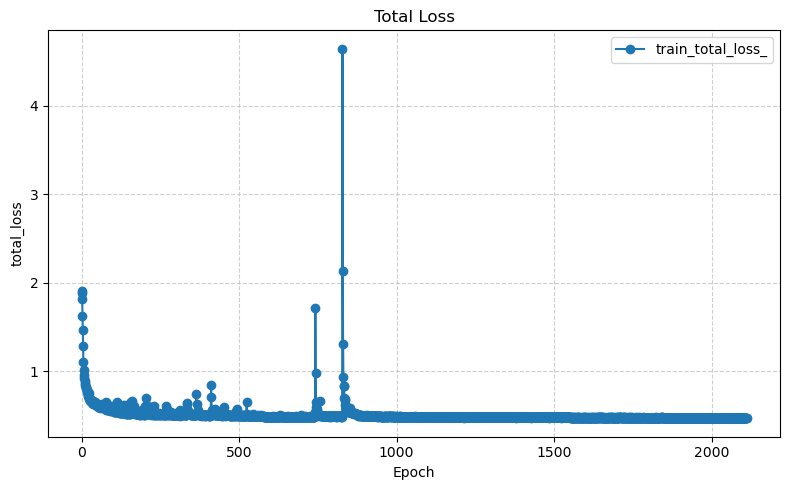

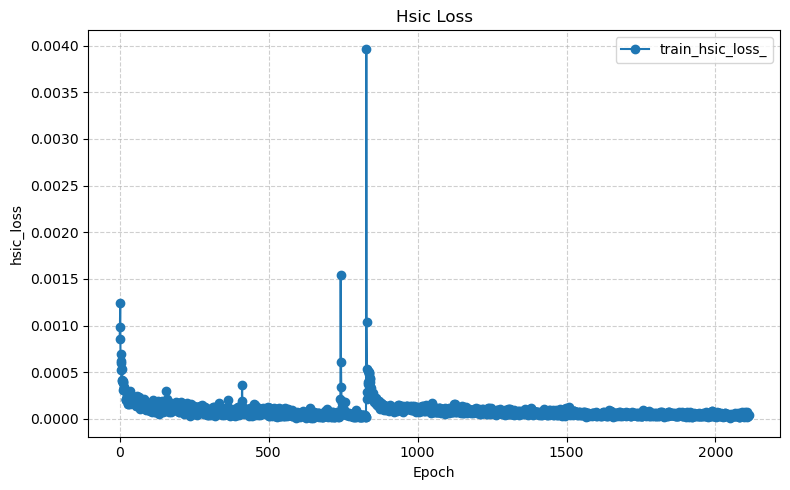

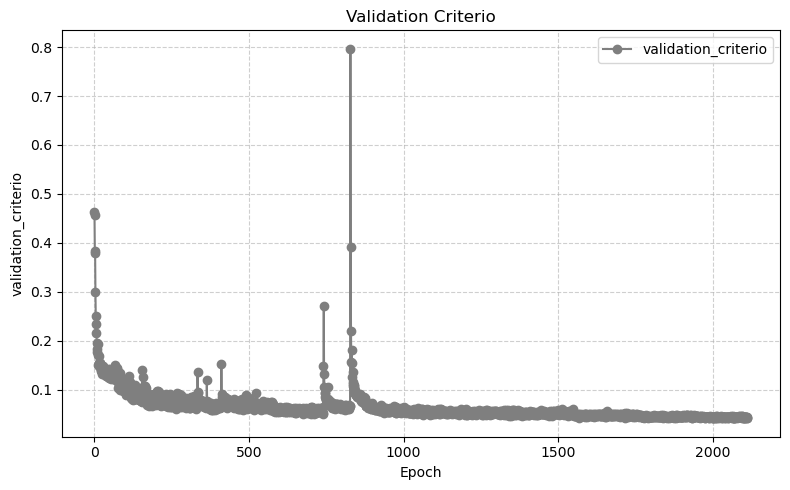

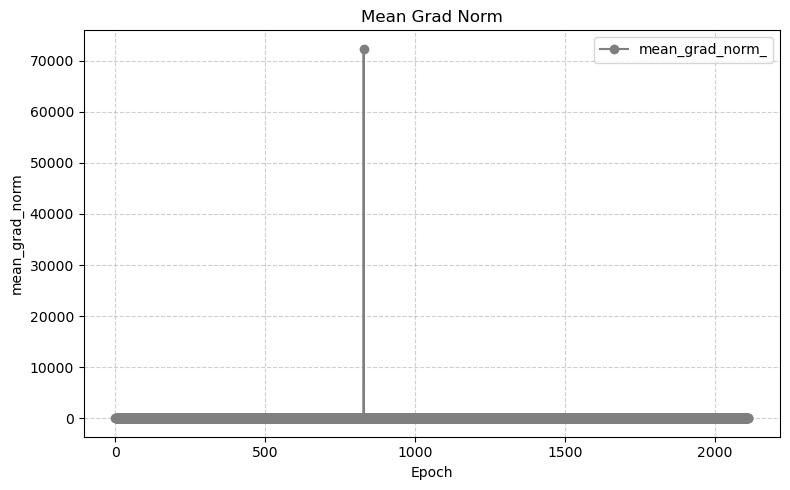

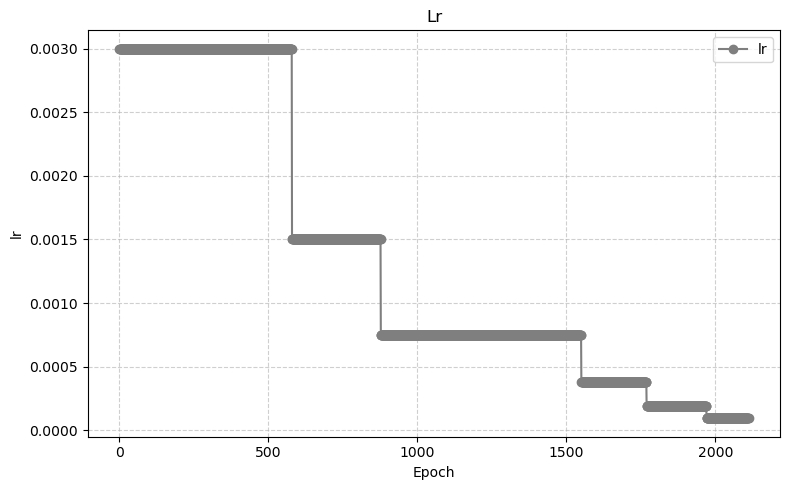

In [58]:
visualize_epoch_metrics(
 save_dir_path,
["val_prediction_loss_", "val_prediction_loss_training_set", "train_total_loss_", "train_hsic_loss_" , "validation_criterio", "mean_grad_norm_", "lr"],
plot_on_same_graph=True,
verbose=True,
specific_epochs=None
)



Final-epoch (2111) val_train_pred_loss by frac_regular tercile:
  frac_regular in [0.000,0.140]: n= 96  mean=0.0332  median=0.0308  max=0.0894
  frac_regular in [0.140,0.596]: n= 94  mean=0.0352  median=0.0333  max=0.0929
  frac_regular in [0.596,1.000]: n= 98  mean=0.0309  median=0.0289  max=0.0880


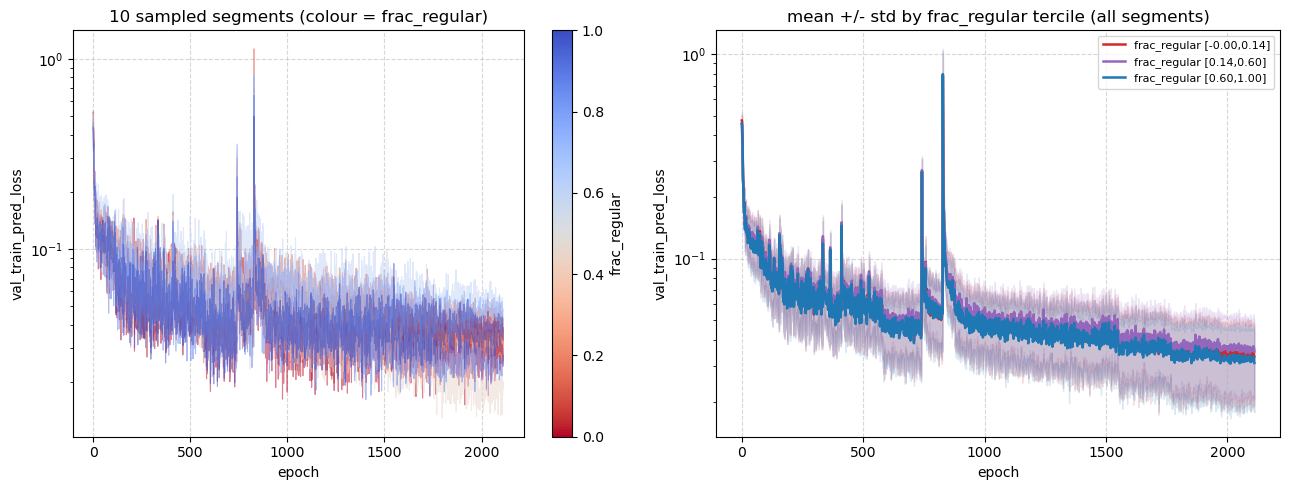

In [59]:
merged = load_segment_progress(save_dir_path, train_seg_id_df)

# two-panel plot: left = sampled individual segment curves (colour = frac_regular),
# right = mean±std by frac_regular tercile over ALL segments
fig = plot_segment_progress(merged,
                            loss_col='val_train_pred_loss',
                            n_sample_lines=10,       # how many individual curves on the left
                            color_by='frac_regular', # continuous colour in [0,1]
                            n_bins=3,                # terciles: chaotic / mixed / regular
                            log_y=True)

# text summary: final-epoch loss stats per tercile
summarise_segment_progress(merged, color_by='frac_regular', n_bins=3)

In [ ]:
n        = 2
POS_COLS = ("x", "y")
MOM_COLS = ("px", "py")
Tmax     = 8.563

In [40]:
device = "cuda"
mapping_net = SimpleStackedHamiltonianNetwork_general(
    n=n,
    n_layers=10,
    hidden_dims=[33, 60, 32],
    n_hidden_layers=None,               # ignored when hidden_dims is a list
    activation='gelu',
    activation_params=None,
    final_activation=None,              # linear output on final HJL
    final_activation_only_on_final_layer=True,
    weight_init='orthogonal',           # Saxe init (paper)
    weight_init_params=None,
    bias_init='zeros',
    bias_init_value=0.0,
    use_bias=True,
    use_layer_norm=False,
    # a reparam: a in [0.5, 2.0], a_k = 0.1, induced-a mean 1.6, std = 10% of mean
    a_eps_min=0.5,
    a_eps_max=2.0,
    a_k=0.1,
    step_1_a_mean_innit=1.6,
    step_2_a_mean_innit=1.6,
    a_std_ratio=0.1,
    # gamma ~ N(2.0, 0.04)  (variance 0.04)
    step_1_gamma_mean_innit=2.0,
    step_2_gamma_mean_innit=2.0,
    gamma_variance=0.04,
    # c1 ~ N(+0.1, 0.01) for step_1 / N(-0.1, 0.01) for step_2 (paper: c_{1,i}, c'_{1,i})
    step_1_c1_mean_innit=0.1,
    step_2_c1_mean_innit=-0.1,
    c1_variance=0.01,
    # c2 ~ N(-0.1, 0.01) for step_1 / N(+0.1, 0.01) for step_2 (paper: c_{2,i}, c'_{2,i})
    step_1_c2_mean_innit=-0.1,
    step_2_c2_mean_innit=0.1,
    c2_variance=0.01,
    seed=42,
).to(device)

In [41]:


checkpoint_path = os.path.join(save_dir_path, "best_model.pt")

epoch, extra_info, best_val_loss = load_checkpoint(
    path=checkpoint_path,
    mapping_net=mapping_net,
    device=device,
    optimizer=None,
    scheduler=None,
)

print(f"Checkpoint epoch: {epoch}")

inverse_net = InverseStackedHamiltonianNetwork_general(forward_network=mapping_net)


Successfully loaded model
Checkpoint epoch: 2111


In [134]:
canonicity_results = test_canonical_transformation_on_trajectory_general(
    get_data_from_trajectory_id,
    compute_jacobian_functional_general,
    compute_symplectic_product_general,
    test_id_df,
    test_df,
    57,
    mapping_net,
    inverse_net,
    device,
    Tmax,
    n,
    pos_cols=POS_COLS,
    mom_cols=MOM_COLS,
    tolerance=1e-5,
    verbose=True,
)

=== Canonical Transformation Test — Trajectory 57 ===
(n=2, Jacobians are 4x4, 6 segment(s), 334 total points, tolerance=1.0e-05)

MappingNet: d(Q,P)/d(q,p)
  ✓ All 334 points pass (max residual: 1.25e-06)
  Residual max|M^T Ω M - Ω| per point:
    Mean:   2.88e-07 (std=1.59e-07)
    Median: 2.38e-07 [IQR: 1.79e-07, 3.58e-07]
    Min:    3.73e-08
    Max:    1.25e-06

InverseNet: d(q,p)/d(Q,P)
  ✓ All 334 points pass (max residual: 5.25e-06)
  Residual max|M^T Ω M - Ω| per point:
    Mean:   1.12e-06 (std=9.54e-07)
    Median: 9.54e-07 [IQR: 4.49e-07, 1.43e-06]
    Min:    5.96e-08
    Max:    5.25e-06

=== Table row (Task = trajectory 57) ===
  M  max    = 1.25e-06
  M  median = 2.38e-07
  M^-1 max    = 5.25e-06
  M^-1 median = 9.54e-07
  LaTeX: 1.25e-06 & 2.38e-07 & 5.25e-06 & 9.54e-07 \\


In [43]:
print(f"Number of parameters are: {count_parameters(mapping_net)}, with number of training samples: {train_seg_df.shape[0]}\nThat is a ratio of parameters/samples of: {count_parameters(mapping_net)/train_seg_df.shape[0]}")

Number of parameters are: 83260, with number of training samples: 16032
That is a ratio of parameters/samples of: 5.193363273453094


In [ ]:

with open("benchmark_outputs/hjn_task4_multiple_periods_final.pkl", "rb") as f:
    time_results_multiple_periods = pickle.load(f)

In [44]:
all_trajectories_results_multiple_periods = test_model_all_observations_all_trajectories_general(
    get_data_from_trajectory_id,
    prediction_loss_euclidean_general,
    test_id_df,
    test_df,
    mapping_net,
    inverse_net,
    device,
    Tmax,
    n,
    pos_cols=POS_COLS,
    mom_cols=MOM_COLS,
    bootstrap_B=10000,
    confidence_level=0.95,
    normalize_by_energy=True,
    verbose=True,
)

Observation index 0/333, mean loss across trajectories: 0.259430
Observation index 1/333, mean loss across trajectories: 0.261505
Observation index 2/333, mean loss across trajectories: 0.259238
Observation index 3/333, mean loss across trajectories: 0.251953
Observation index 4/333, mean loss across trajectories: 0.244240
Observation index 5/333, mean loss across trajectories: 0.240640
Observation index 6/333, mean loss across trajectories: 0.233949
Observation index 7/333, mean loss across trajectories: 0.231532
Observation index 8/333, mean loss across trajectories: 0.235893
Observation index 9/333, mean loss across trajectories: 0.240246
Observation index 10/333, mean loss across trajectories: 0.242073
Observation index 11/333, mean loss across trajectories: 0.241813
Observation index 12/333, mean loss across trajectories: 0.245694
Observation index 13/333, mean loss across trajectories: 0.248874
Observation index 14/333, mean loss across trajectories: 0.246779
Observation index 15

In [45]:
#SAVE

with open("./prediction_results_all_trajectories/task_4_results_multiple_periods.pkl", "wb") as f:
    pickle.dump(all_trajectories_results_multiple_periods, f)

In [ ]:
#LOAD
with open("./prediction_results_all_trajectories/task_4_results_multiple_periods.pkl", "rb") as f:
    all_trajectories_results_multiple_periods = pickle.load(f)


=== Raw Statistics (loss) ===
Per-trajectory summary: median across obs. choices
Mean of medians: 0.166353
Std of medians: 0.093434
Median of medians: 0.137592
IQR of medians: [0.088833, 0.260707]
95% BCa CI for mean of medians (over trajectories): [0.126711, 0.215861]
N_traj=16, N_obs=334

=== Normalized Statistics (energy-normalized loss L/√E) ===
Per-trajectory summary: median across obs. choices
Mean of medians: 0.507731
Std of medians: 0.264483
Median of medians: 0.418092
IQR of medians: [0.287434, 0.784233]
95% BCa CI for mean of medians (over trajectories): [0.397278, 0.649570]
N_traj=16, N_obs=334


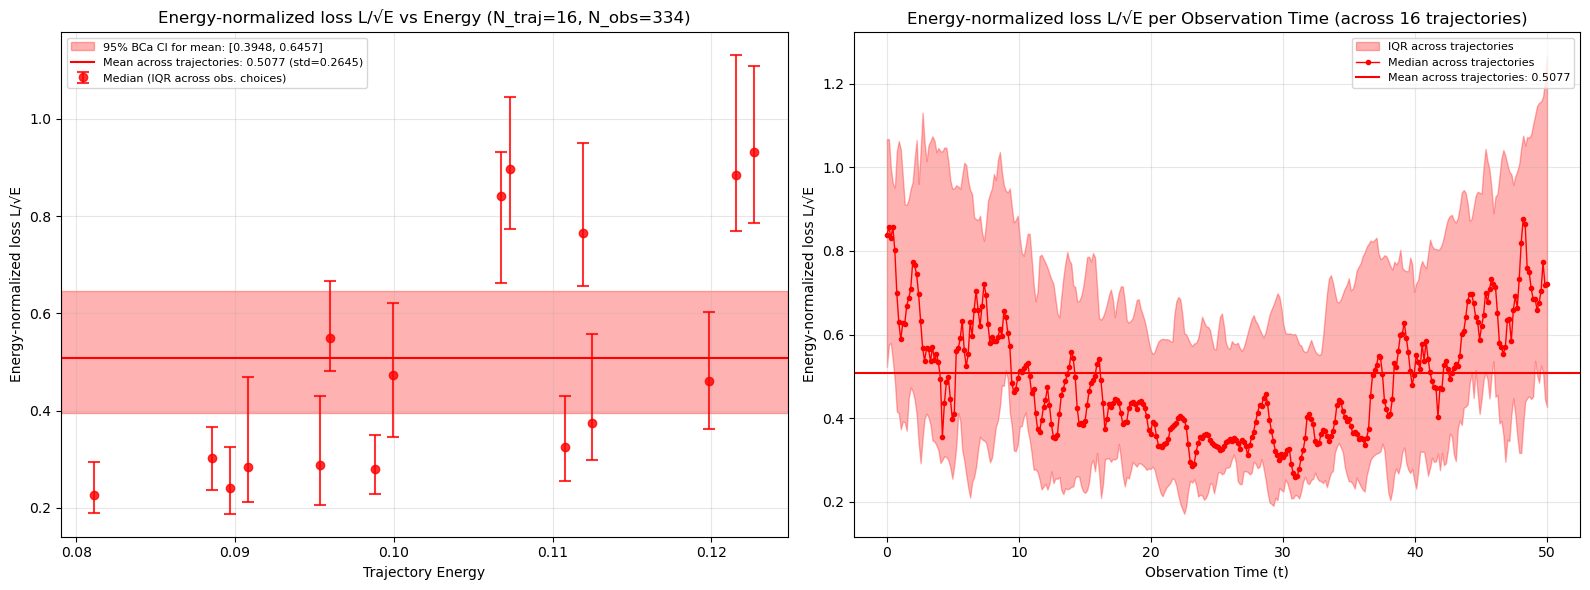

In [ ]:
plot_summary_statistics(all_trajectories_results_multiple_periods, normalized=True, figsize=(16, 6), timing_stats_batch=time_results_multiple_periods['timing_stats'], timing_stats_single=None, band_alpha=0.3)

In [47]:
print(all_trajectories_results_multiple_periods['median_representative_id'])

57


In [49]:
single_trajectory_multiple_periods_results = test_model_varying_observation_single_trajectory_general(
    get_data_from_trajectory_id,
    "mse",
    test_id_df,
    test_df,
    all_trajectories_results_multiple_periods['median_representative_id'],
    mapping_net,
    inverse_net,
    device,
    Tmax,
    n,
    pos_cols=POS_COLS,
    mom_cols=MOM_COLS,
    energy_function=make_energy_henon_heiles(),
    verbose=True,
)

Observation index 0/333, loss: 0.105135
Observation index 1/333, loss: 0.106087
Observation index 2/333, loss: 0.108145
Observation index 3/333, loss: 0.115045
Observation index 4/333, loss: 0.138510
Observation index 5/333, loss: 0.164473
Observation index 6/333, loss: 0.127131
Observation index 7/333, loss: 0.074248
Observation index 8/333, loss: 0.063523
Observation index 9/333, loss: 0.054352
Observation index 10/333, loss: 0.040582
Observation index 11/333, loss: 0.032756
Observation index 12/333, loss: 0.033244
Observation index 13/333, loss: 0.036878
Observation index 14/333, loss: 0.038428
Observation index 15/333, loss: 0.033529
Observation index 16/333, loss: 0.020054
Observation index 17/333, loss: 0.007162
Observation index 18/333, loss: 0.011993
Observation index 19/333, loss: 0.009273
Observation index 20/333, loss: 0.007877
Observation index 21/333, loss: 0.010567
Observation index 22/333, loss: 0.013987
Observation index 23/333, loss: 0.015642
Observation index 24/333, 

In [50]:
#SAVE

with open("./prediction_results_single_trajectory/task_4_single_traj_results_multiple_periods.pkl", "wb") as f:
    pickle.dump(single_trajectory_multiple_periods_results, f)

In [ ]:
#LOAD
with open("./prediction_results_single_trajectory/task_4_single_traj_results_multiple_periods.pkl", "rb") as f:
    single_trajectory_multiple_periods_results = pickle.load(f)

In [51]:
obs_idx = 0

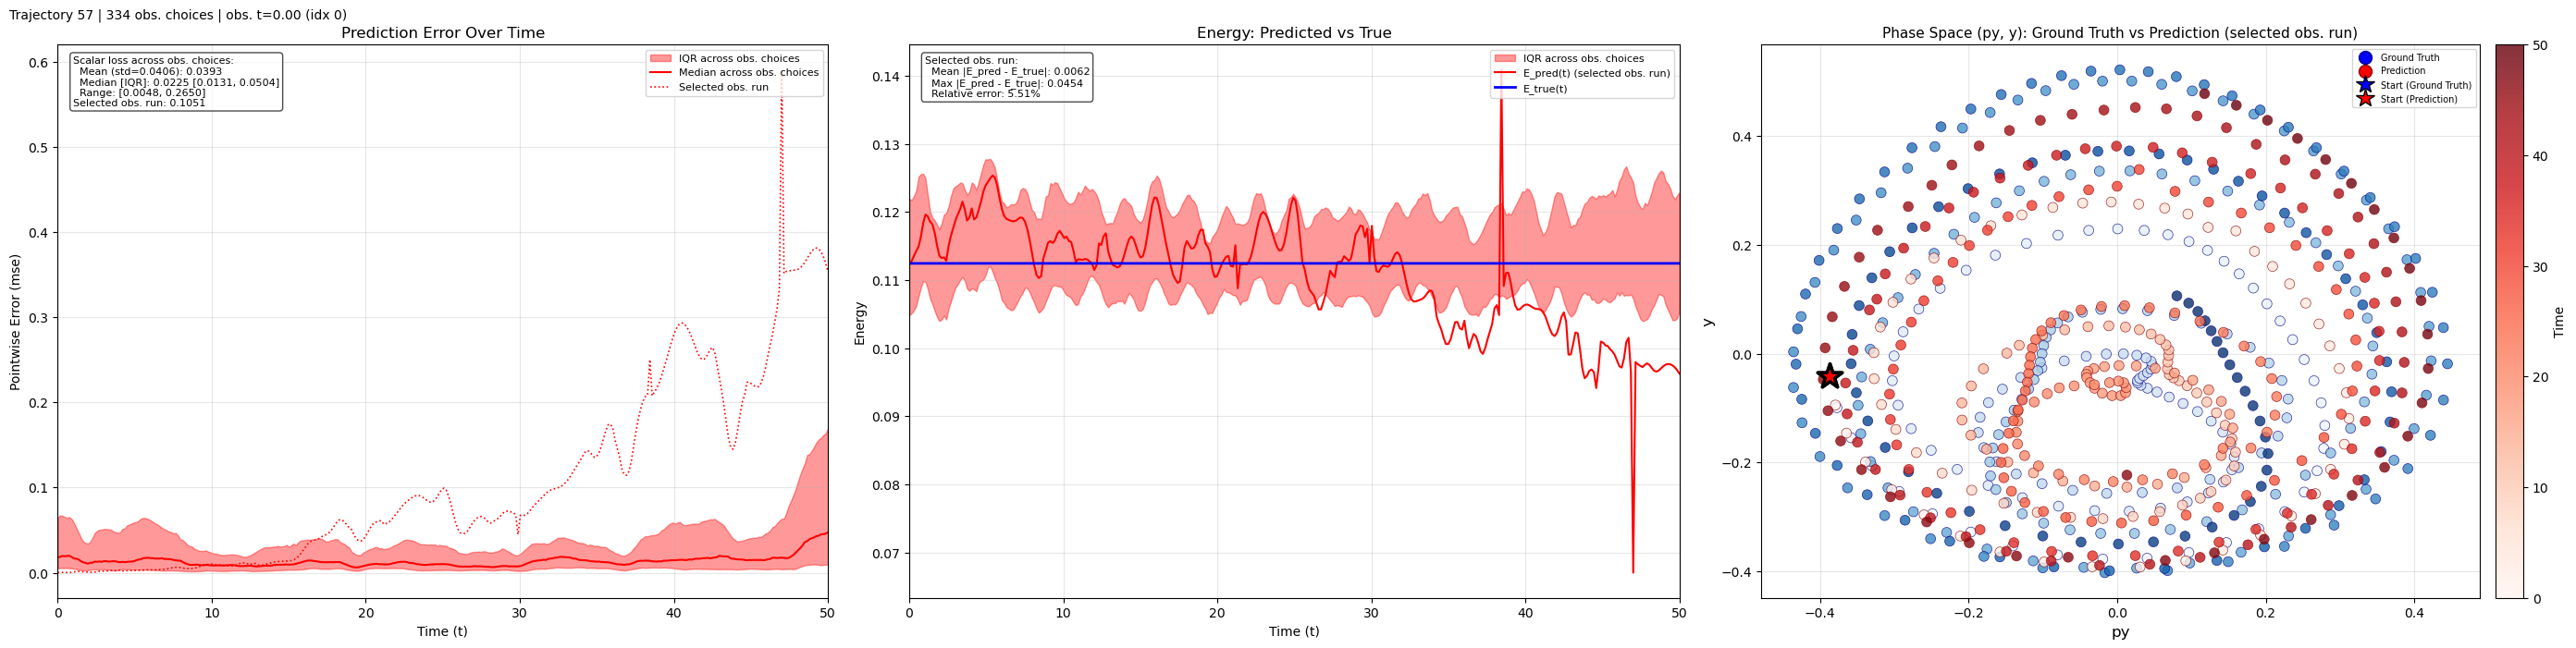

In [52]:
plot_varying_observation_results_general(
    single_trajectory_multiple_periods_results, obs_idx, phase_coords=("py", "y"), figsize=(28, 7),
    connect_points=False, iqr_alpha=0.4,
)

In [123]:


with open("all_dataframes_HH_portable_high_energy.pkl", "rb") as f:
    portable = pickle.load(f)

loaded_dfs_high_energy = {}
for name, d in portable.items():
    df = pd.DataFrame(d["data"], columns=d["columns"])
    df.index = pd.Index(d["index_values"], name=d["index_name"])
    loaded_dfs_high_energy[name] = df

# Verify shapes survived the round trip
print(f"{'name':<20}{'loaded shape':<16}status")
for name, d in portable.items():
    got, exp = loaded_dfs_high_energy[name].shape, d["shape"]
    status = "OK" if got == exp else f"!! MISMATCH (expected {exp})"
    print(f"{name:<20}{str(got):<16}{status}")

name                loaded shape    status
test_df_high_energy (1840, 6)       OK
test_id_df_high_energy(16, 9)         OK


In [124]:

test_df_high_energy         = loaded_dfs_high_energy["test_df_high_energy"]

test_id_df_high_energy      = loaded_dfs_high_energy["test_id_df_high_energy"]

In [133]:
print(f"The max energy of a trajectory in the training set is: {train_id_df['energy'].max():.3f}\nThe high energy testing set has energies in the range: {test_id_df_high_energy['energy'].min():.3f}-{test_id_df_high_energy['energy'].max():.3f}")

The max energy of a trajectory in the training set is: 0.125
The high energy testing set has energies in the range: 0.130-0.167


In [ ]:

with open("benchmark_outputs/hjn_task4_high_energy.pkl", "rb") as f:
    time_results_high_energy = pickle.load(f)

In [125]:
all_trajectories_results_high_energy = test_model_all_observations_all_trajectories_general(
    get_data_from_trajectory_id,
    prediction_loss_euclidean_general,
    test_id_df_high_energy,
    test_df_high_energy,
    mapping_net,
    inverse_net,
    device,
    Tmax,
    n,
    pos_cols=POS_COLS,
    mom_cols=MOM_COLS,
    bootstrap_B=10000,
    confidence_level=0.95,
    normalize_by_energy=True,
    verbose=True,
)

Observation index 0/114, mean loss across trajectories: 0.338053
Observation index 1/114, mean loss across trajectories: 0.332781
Observation index 2/114, mean loss across trajectories: 0.326224
Observation index 3/114, mean loss across trajectories: 0.319073
Observation index 4/114, mean loss across trajectories: 0.312574
Observation index 5/114, mean loss across trajectories: 0.306517
Observation index 6/114, mean loss across trajectories: 0.300328
Observation index 7/114, mean loss across trajectories: 0.293789
Observation index 8/114, mean loss across trajectories: 0.288731
Observation index 9/114, mean loss across trajectories: 0.284898
Observation index 10/114, mean loss across trajectories: 0.281675
Observation index 11/114, mean loss across trajectories: 0.279892
Observation index 12/114, mean loss across trajectories: 0.278549
Observation index 13/114, mean loss across trajectories: 0.277453
Observation index 14/114, mean loss across trajectories: 0.275458
Observation index 15

In [126]:
#SAVE

with open("./prediction_results_all_trajectories/task_4_results_high_energy.pkl", "wb") as f:
    pickle.dump(all_trajectories_results_high_energy, f)


=== Raw Statistics (loss) ===
Per-trajectory summary: median across obs. choices
Mean of medians: 0.222378
Std of medians: 0.124042
Median of medians: 0.178678
IQR of medians: [0.146508, 0.270033]
95% BCa CI for mean of medians (over trajectories): [0.174985, 0.297697]
N_traj=16, N_obs=115

=== Normalized Statistics (energy-normalized loss L/√E) ===
Per-trajectory summary: median across obs. choices
Mean of medians: 0.574843
Std of medians: 0.315169
Median of medians: 0.446613
IQR of medians: [0.377293, 0.697266]
95% BCa CI for mean of medians (over trajectories): [0.450615, 0.755368]
N_traj=16, N_obs=115


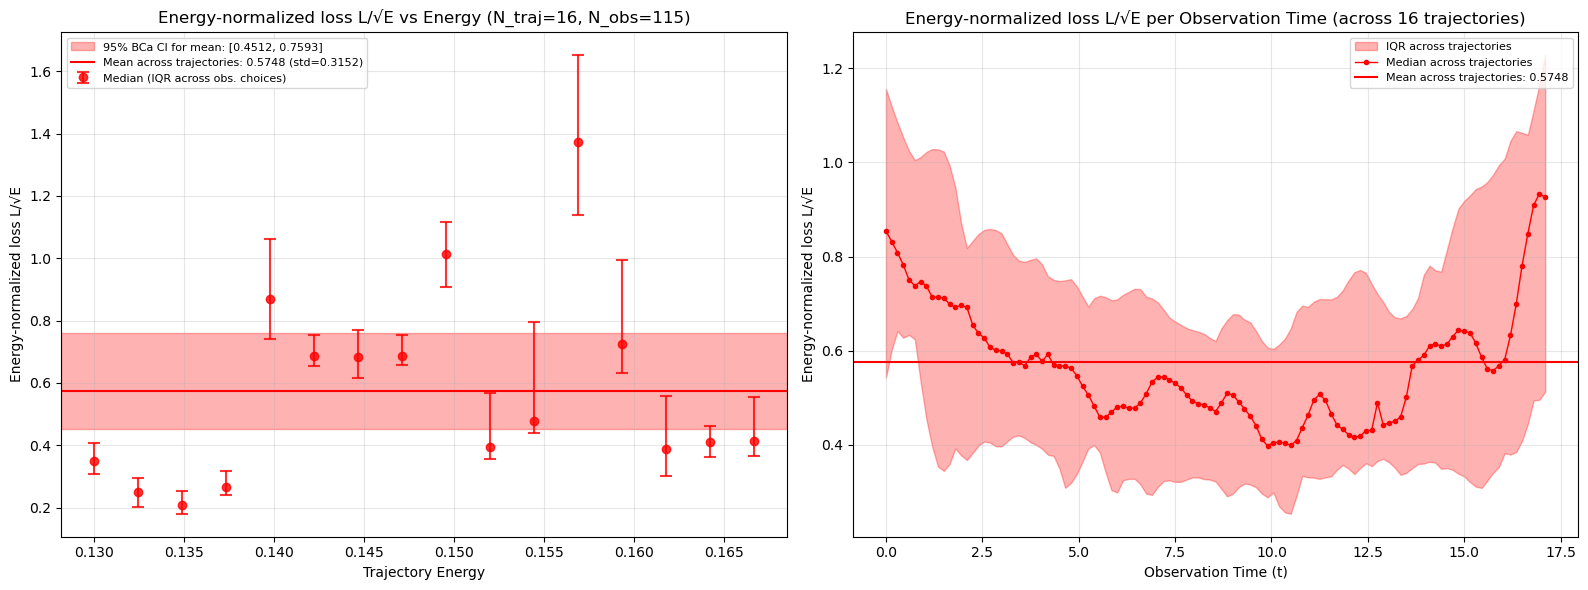

In [ ]:
plot_summary_statistics(all_trajectories_results_high_energy, normalized=True, figsize=(16, 6), timing_stats_batch=time_results_high_energy['timing_stats'], timing_stats_single=None, band_alpha=0.3)

In [128]:
print(all_trajectories_results_high_energy['median_representative_id'])

10


In [129]:
single_trajectory_high_energy_results = test_model_varying_observation_single_trajectory_general(
    get_data_from_trajectory_id,
    "mse",
    test_id_df_high_energy,
    test_df_high_energy,
    all_trajectories_results_high_energy['median_representative_id'],
    mapping_net,
    inverse_net,
    device,
    Tmax,
    n,
    pos_cols=POS_COLS,
    mom_cols=MOM_COLS,
    energy_function=make_energy_henon_heiles(),
    verbose=True,
)

Observation index 0/114, loss: 0.192925
Observation index 1/114, loss: 0.182313
Observation index 2/114, loss: 0.174607
Observation index 3/114, loss: 0.171171
Observation index 4/114, loss: 0.166346
Observation index 5/114, loss: 0.158915
Observation index 6/114, loss: 0.149076
Observation index 7/114, loss: 0.136375
Observation index 8/114, loss: 0.129045
Observation index 9/114, loss: 0.128733
Observation index 10/114, loss: 0.130788
Observation index 11/114, loss: 0.132782
Observation index 12/114, loss: 0.133124
Observation index 13/114, loss: 0.128017
Observation index 14/114, loss: 0.117804
Observation index 15/114, loss: 0.103377
Observation index 16/114, loss: 0.088469
Observation index 17/114, loss: 0.080746
Observation index 18/114, loss: 0.079452
Observation index 19/114, loss: 0.083289
Observation index 20/114, loss: 0.086741
Observation index 21/114, loss: 0.086762
Observation index 22/114, loss: 0.083236
Observation index 23/114, loss: 0.076795
Observation index 24/114, 

In [130]:
#SAVE

with open("./prediction_results_single_trajectory/task_4_single_traj_results_high_energy.pkl", "wb") as f:
    pickle.dump(single_trajectory_high_energy_results, f)

In [131]:
obs_idx = 0

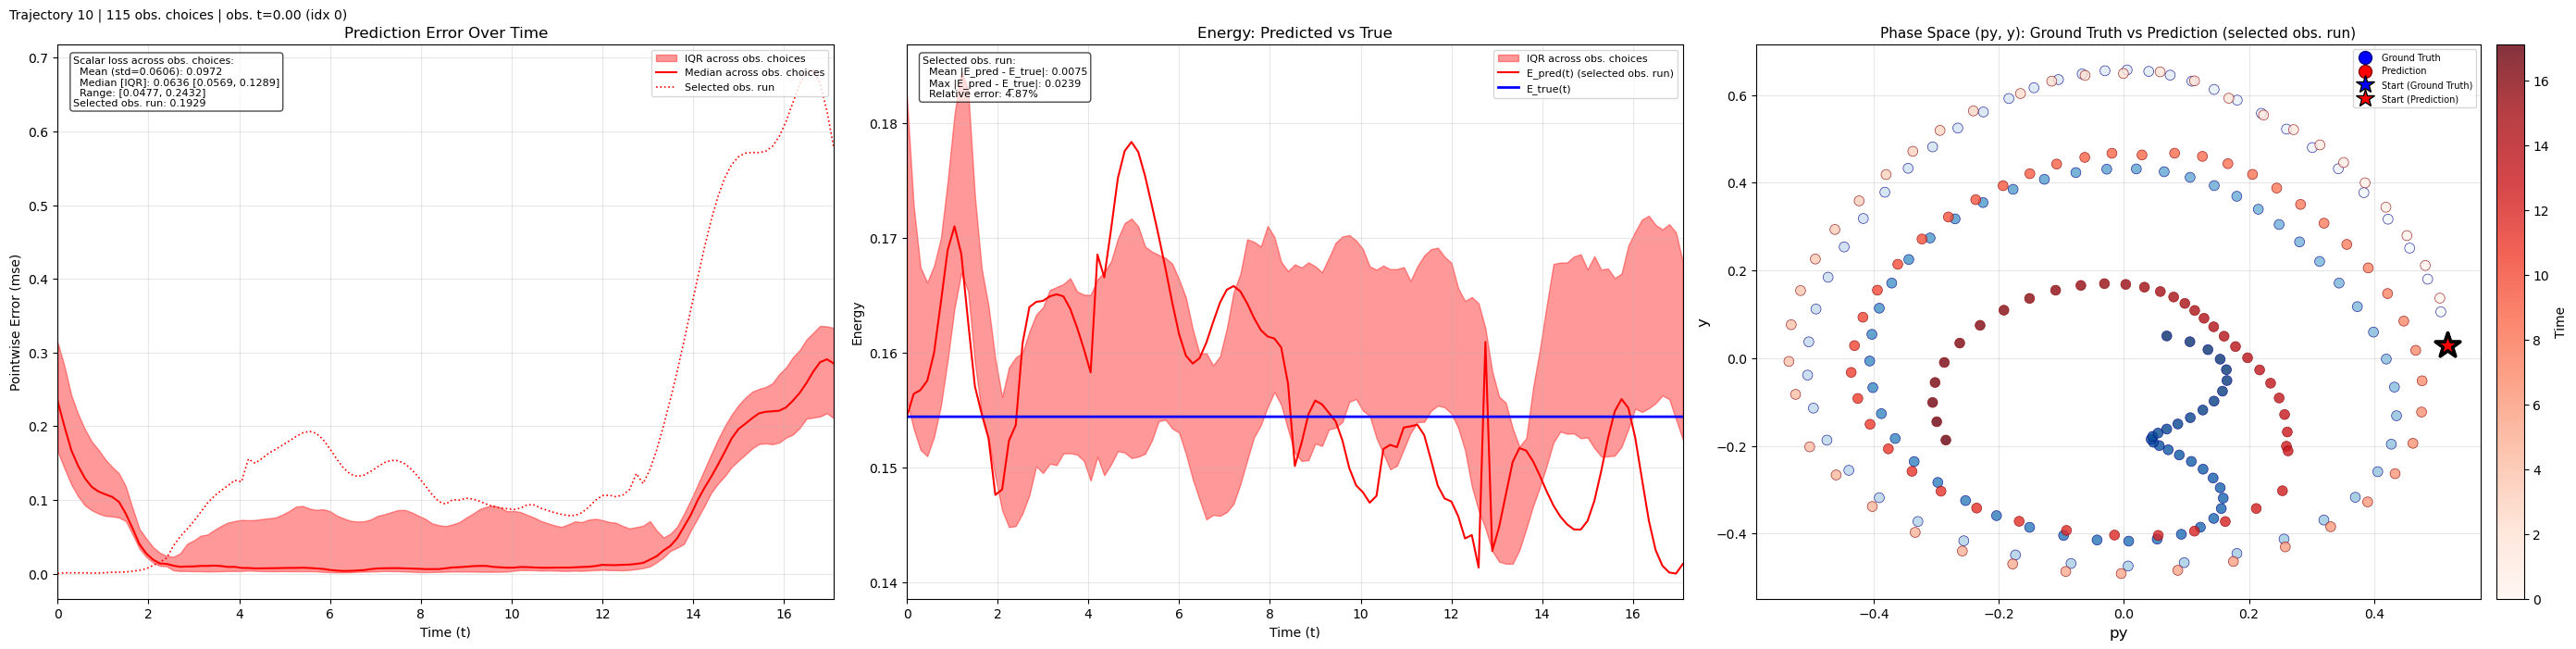

In [132]:
plot_varying_observation_results_general(
    single_trajectory_high_energy_results, obs_idx, phase_coords=("py", "y"), figsize=(28, 7),
    connect_points=False, iqr_alpha=0.4,
)

In [37]:
def print_column_stats(df, columns=("x", "y", "px", "py")):
    for col in columns:
        if col in df.columns:
            print(
                f"{col:>2}: "
                f"mean={df[col].mean():.6f}, "
                f"min={df[col].min():.6f}, "
                f"max={df[col].max():.6f}"
            )
        else:
            print(f"{col:>2}: column not found")

print_column_stats(train_seg_df)

 x: mean=0.005383, min=-0.555733, max=0.560843
 y: mean=-0.008078, min=-0.426329, max=0.597720
px: mean=0.000288, min=-0.493889, max=0.491642
py: mean=0.000596, min=-0.471372, max=0.478218


In [120]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold


# Training-range bounds of the Henon-Heiles data (from train_seg_df).
HH_COORD_BOUNDS = {
    "x":  (-0.555733, 0.560843),
    "y":  (-0.426329, 0.597720),
    "px": (-0.493889, 0.491642),
    "py": (-0.471372, 0.478218),
}


def coord_bounds_from_df(df, pos_cols=("x", "y"), mom_cols=("px", "py")):
    """Recompute coordinate bounds from a training dataframe, so they cannot go
    stale if the data is regenerated. Returns a dict in HH_COORD_BOUNDS form."""
    return {c: (float(df[c].min()), float(df[c].max()))
            for c in list(pos_cols) + list(mom_cols)}


# ======================================================================
# Grid construction (Henon-Heiles)
# ======================================================================
def hh_potential(x, y, lam=1.0):
    """V(x, y) = 1/2 (x^2 + y^2) + lam (x^2 y - y^3/3)."""
    return 0.5 * (x**2 + y**2) + lam * (x**2 * y - (1 / 3.) * y**3)


def sample_hh_states_at_energy(E, n_states, rng, lam=1.0,
                               coord_bounds=HH_COORD_BOUNDS, max_tries=100000):
    """
    Draw `n_states` initial conditions with H(q, p) = E exactly.

    Same product procedure as HenonHeilesPhaseSpace._sample_ic (position uniform
    in the admissible region {V <= E}, momentum magnitude fixed by energy,
    direction uniform on the circle), with two changes:
      * position is drawn from the TRAINING box rather than the generator's
        wider sampling box, and
      * the whole draw is rejected if any of x, y, px, py falls outside the
        training range.
    Rejecting the whole IC (rather than redrawing only the direction) keeps the
    position/direction product intact instead of biasing the direction
    distribution where the momentum constraint binds.

    Returns q (n_states, 2), p (n_states, 2).
    """
    xlo, xhi = coord_bounds["x"]
    ylo, yhi = coord_bounds["y"]
    pxlo, pxhi = coord_bounds["px"]
    pylo, pyhi = coord_bounds["py"]

    q = np.empty((n_states, 2))
    p = np.empty((n_states, 2))
    got = 0
    tries = 0
    while got < n_states:
        tries += 1
        if tries > max_tries:
            raise RuntimeError(
                f"Could not draw {n_states} in-range states at E={E} after "
                f"{max_tries} tries (got {got}). Check coord_bounds vs the energy band.")
        x = rng.uniform(xlo, xhi)
        y = rng.uniform(ylo, yhi)
        v = hh_potential(x, y, lam)
        if v > E:
            continue
        p_mag = np.sqrt(max(2.0 * (E - v), 0.0))
        theta = rng.uniform(0.0, 2.0 * np.pi)
        px, py = p_mag * np.cos(theta), p_mag * np.sin(theta)
        if not (pxlo <= px <= pxhi and pylo <= py <= pyhi):
            continue
        q[got] = (x, y)
        p[got] = (px, py)
        got += 1
    return q, p


def build_hh_grid(E_lo, E_hi, n_energies=40, n_states_per_energy=200,
                  lam=1.0, coord_bounds=HH_COORD_BOUNDS, seed=0):
    """
    Build the sampled state set: `n_energies` energies evenly spaced over
    [E_lo, E_hi], each with `n_states_per_energy` states drawn on that exact
    energy shell and inside the training range.

    Unlike the n = 1 case there is no analytic (E, phi) -> (q, p) map, so this
    is a sampled set rather than a regular grid in conserved-quantity space.

    Returns E (N,), q (N, 2), p (N, 2) with N = n_energies * n_states_per_energy.
    """
    rng = np.random.default_rng(seed)
    energies = np.linspace(E_lo, E_hi, n_energies)
    qs, ps, Es = [], [], []
    for E in energies:
        qi, pi = sample_hh_states_at_energy(
            float(E), n_states_per_energy, rng, lam=lam, coord_bounds=coord_bounds)
        qs.append(qi)
        ps.append(pi)
        Es.append(np.full(n_states_per_energy, float(E)))
    return np.concatenate(Es), np.concatenate(qs, 0), np.concatenate(ps, 0)


# ======================================================================
# Encoding
# ======================================================================
def encode_at_reference_time_general(mapping_net, q, p, device, n, reference_time=0.0):
    """
    Encode states at a single reference time.

    No torch.no_grad(): the HJL forward uses autograd internally; outputs are
    .detach()ed instead.

    Args:
        q, p: (N, n) arrays
        n: int, degrees of freedom
        reference_time: float, the time input for every state
    Returns:
        Q, P: (N, n) float64 arrays
    """
    import torch
    q = np.asarray(q, np.float32).reshape(-1, n)
    p = np.asarray(p, np.float32).reshape(-1, n)
    q_t = torch.as_tensor(q, device=device)                              # (N, n)
    p_t = torch.as_tensor(p, device=device)                              # (N, n)
    t_t = torch.full((q_t.shape[0], 1), float(reference_time),
                     device=device, dtype=torch.float32)                 # (N, 1)
    Q, P, _ = mapping_net(q_t, p_t, t_t)
    return (Q.detach().cpu().numpy().astype(float),
            P.detach().cpu().numpy().astype(float))


def latent_names(n):
    """Feature names for the 2n latents, grouped as (Q_1..Q_n, P_1..P_n)."""
    return [f"Q{i+1}" for i in range(n)] + [f"P{i+1}" for i in range(n)]


def encode_hh_grid(mapping_net, device, E_lo, E_hi, n=2,
                   n_energies=40, n_states_per_energy=200, lam=1.0,
                   coord_bounds=HH_COORD_BOUNDS, seed=0, reference_time=0.0):
    """
    Build the state set and encode it at `reference_time` (t = 0 by default,
    since each sampled state is the t = 0 state of a trajectory of energy E).

    Returns dict with E (N,), q (N,n), p (N,n), feats (N,2n), band, n, names.
    """
    E, q, p = build_hh_grid(E_lo, E_hi, n_energies, n_states_per_energy,
                            lam=lam, coord_bounds=coord_bounds, seed=seed)
    Q, P = encode_at_reference_time_general(mapping_net, q, p, device, n, reference_time)
    return dict(E=E, q=q, p=p,
                feats=np.column_stack([Q, P]),          # (N, 2n) grouped ordering
                band=(E_lo, E_hi), n=n, names=latent_names(n),
                n_energies=n_energies, n_states_per_energy=n_states_per_energy)


# ======================================================================
# Core: out-of-fold prediction, equations
# ======================================================================
def _r2(y, yhat):
    y = np.asarray(y, float)
    return 1.0 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)


def _poly(degree, scale=False):
    """Polynomial least-squares read-out. `scale` toggles input standardisation:
    it leaves predictions and R^2 unchanged (an invertible affine reparameterisation
    of the features) and only changes coefficient values, so it is OFF by default
    so that the fitted model IS the equation reported in raw latent units. Turn it
    ON only if a high-degree solve is ill-conditioned; it never affects results."""
    steps = [StandardScaler()] if scale else []
    steps += [PolynomialFeatures(degree, include_bias=True),
              LinearRegression(fit_intercept=False)]
    return make_pipeline(*steps)


def _oof_scalar(feats, y, degree, n_splits=5, seed=0, scale=False):
    kf = KFold(n_splits, shuffle=True, random_state=seed)
    y = np.asarray(y, float)
    pred = np.zeros_like(y)
    for tr, te in kf.split(feats):
        pred[te] = _poly(degree, scale).fit(feats[tr], y[tr]).predict(feats[te])
    return pred


def err_stats(abs_err):
    """Descriptive spread (no distributional assumption, no bootstrap)."""
    a = np.asarray(abs_err, float)
    q25, med, q75, p95 = np.percentile(a, [25, 50, 75, 95])
    return dict(median=med, p25=q25, p75=q75, p95=p95, mean=a.mean())


def _terms(names, coef):
    """Format a polynomial as a coefficient string in raw latent units."""
    parts = []
    for nm, c in zip(names, coef):
        if nm == "1":
            parts.append(f"{c:+.4f}")
        else:
            parts.append(f"{c:+.4f}·{nm.replace(' ', '·')}")
    return " ".join(parts)


def energy_equation_general(feats, E, degree, n, scale=False):
    """
    Fit the energy read-out and expose both its coefficients (raw latent units,
    the displayed equation) and the fitted model itself, so the SAME object can
    be reused as the time-shift instrument.

    For degree 2 we also return the 2n x 2n quadratic part, its eigenvalues, and
    the location/value of its stationary point. A positive-definite quadratic part
    means bounded (ellipsoidal) level sets in the 2n-dimensional latent space for
    every value above the minimum -- the n-dimensional generalization of the
    closed-ellipse argument at n = 1.
    """
    names_in = latent_names(n)
    model = _poly(degree, scale).fit(feats, E)
    pf = model.named_steps["polynomialfeatures"]
    names = pf.get_feature_names_out(names_in)
    coef = model.named_steps["linearregression"].coef_
    out = dict(names=names, coef=coef, degree=degree, model=model, n=n)

    if degree == 2 and feats.shape[1] == 2 * n and not scale:
        d = dict(zip(names, coef))
        D = 2 * n
        M = np.zeros((D, D))
        for i in range(D):
            M[i, i] = d[f"{names_in[i]}^2"]
            for j in range(i + 1, D):
                key = f"{names_in[i]} {names_in[j]}"
                M[i, j] = M[j, i] = d[key] / 2.0
        ell = np.array([d[names_in[i]] for i in range(D)])
        const = d["1"]
        eig = np.linalg.eigvalsh(M)
        posdef = bool(eig.min() > 0)
        out.update(M=M, ell=ell, const=const, eig=eig, posdef=posdef)
        if posdef:
            z_star = -0.5 * np.linalg.solve(M, ell)
            E_min = float(const + ell @ z_star + z_star @ M @ z_star)
            out.update(z_star=z_star, E_min=E_min)
    return out


# ======================================================================
# Reporters
# ======================================================================
def _fmt(s):
    return f"{s['median']:.4f} [{s['p25']:.4f}, {s['p75']:.4f}] p95={s['p95']:.4f}"


def report_energy_recovery_general(res_train, name="HJN", degrees=(1, 2, 3, 4),
                                   scale=False):
    """R^2 ladder + descriptive error field for the energy read-out,
    in-distribution (5-fold cross-validated, out-of-fold predictions)."""
    ft, Et = res_train["feats"], res_train["E"]
    n = res_train["n"]
    bar = "=" * 78
    print(f"\n{bar}\n[{name}]  ENERGY RECOVERY   n={n}, {ft.shape[1]} latents "
          f"{res_train['names']},  {ft.shape[0]} states, E in {res_train['band']}\n{bar}")
    print(f"{'deg':>3} | {'CV R2':>9} || |dE| med[IQR] p95 (rel%)")
    for dg in degrees:
        oof = _oof_scalar(ft, Et, dg, scale=scale)
        n_terms = PolynomialFeatures(dg).fit(ft[:1]).n_output_features_
        rel = np.median(np.abs(Et - oof) / np.abs(Et)) * 100
        print(f"{dg:>3} | {_r2(Et, oof):>9.4f} || "
              f"{_fmt(err_stats(np.abs(Et - oof)))} ({rel:.1f}%)")


def report_energy_equation_general(res_train, degree, name="HJN"):
    """Print the recovered energy law refit on all states, in raw latent units."""
    ft, Et = res_train["feats"], res_train["E"]
    n = res_train["n"]
    bar = "-" * 78
    print(f"\n{bar}\n[{name}]  RECOVERED ENERGY LAW (degree {degree}, raw latent units; "
          f"coefficients are\ngauge-dependent -- the STRUCTURE is the robust claim)\n{bar}")
    eq = energy_equation_general(ft, Et, degree, n)
    print("  E = " + _terms(eq["names"], np.round(eq["coef"], 4)))
    if "eig" in eq:
        print(f"\n  eigenvalues of the {2*n}x{2*n} quadratic part = {eq['eig'].round(4)}")
        print(f"  positive-definite = {'YES' if eq['posdef'] else 'NO'}"
              f"  (=> bounded/ellipsoidal level sets in {2*n}D)")
        if eq["posdef"]:
            print(f"  stationary point z* = {eq['z_star'].round(4)}")
            print(f"  minimum  E_min = {eq['E_min']:.6f}   "
                  f"(training band {res_train['band']} lies above it: "
                  f"{res_train['band'][0] > eq['E_min']})")
    return eq


# ======================================================================
# Read-out registry
# ======================================================================
def fit_readouts_general(res_train, degrees=(1, 2, 3, 4), scale=False):
    """Fit, once, the energy read-out for every requested degree on the
    reference-time grid, caching the fitted models. These are the SAME models
    whose coefficients report_energy_equation_general displays, so the time-shift
    test applies the displayed equation rather than a separate fit."""
    ft, Et, n = res_train["feats"], res_train["E"], res_train["n"]
    energy = {d: energy_equation_general(ft, Et, d, n, scale)["model"] for d in degrees}
    return dict(energy=energy, degrees=tuple(degrees), n=n)


def predict_energy(readouts, feats, degree):
    return readouts["energy"][degree].predict(feats)


# ======================================================================
# Time-shift test (energy only)
# ======================================================================
def make_tau_grid(T_max, dt=None, n_tau=None):
    """
    Build the tau sweep over [0, T_max].

    dt    : exact spacing; points are k*dt for k = 0.. floor(T_max/dt), so the
            last point is <= T_max. Use this to match the data's own sampling
            step (np.linspace would NOT give the requested spacing).
    n_tau : evenly spaced points including both endpoints.
    Exactly one of dt / n_tau must be given.
    """
    if (dt is None) == (n_tau is None):
        raise ValueError("give exactly one of dt or n_tau")
    if dt is not None:
        k = int(np.floor(T_max / dt + 1e-9))
        return np.arange(k + 1) * dt
    return np.linspace(0.0, T_max, n_tau)


def time_shift_test_energy_general(res_train, mapping_net, device, T_max,
                                   energy_degree, dt=None, n_tau=None,
                                   readouts=None, verbose=True):
    """
    Tests whether the encoder's time action preserves the recovered energy.

    Each sampled state (q0, p0) is the t = 0 state of a trajectory of energy E.
    Holding the state FIXED, we re-encode it at a sweep of times tau in
    [0, T_max], varying only the time input:
        Q(tau), P(tau) = M(q0, p0, tau).
    A correct Hamilton-Jacobi map returns conserved coordinates of the trajectory
    passing through (q0, p0); that trajectory has the SAME energy at every tau.
    Hence the prediction: the recovered energy is flat in tau, slope ~ 0.

    The energy read-out is taken from the cached registry `readouts` (built by
    fit_readouts_general on the reference-time grid; built here if not supplied),
    so the instrument is the displayed equation.

    Note: (state, time) pairs here need not have appeared in training, so the
    test probes the learned CONTINUOUS time dependence, not memorised
    observations. Scope: tau in [0, T_max], the trained temporal domain.

    Returns E_hat (n_tau, N), Q_full (n_tau, N, n), P_full (n_tau, N, n), taus.
    """
    q0, p0 = res_train["q"], res_train["p"]
    E_true = res_train["E"]
    n = res_train["n"]
    N = q0.shape[0]

    if readouts is None:
        readouts = fit_readouts_general(res_train, degrees=(energy_degree,))

    taus = make_tau_grid(T_max, dt=dt, n_tau=n_tau)
    n_t = len(taus)

    E_hat = np.empty((n_t, N))
    Q_full = np.empty((n_t, N, n))
    P_full = np.empty((n_t, N, n))
    for i, tau in enumerate(taus):
        Q, P = encode_at_reference_time_general(mapping_net, q0, p0, device, n, tau)
        E_hat[i] = predict_energy(readouts, np.column_stack([Q, P]), energy_degree)
        Q_full[i] = Q
        P_full[i] = P

    A = np.vstack([taus, np.ones_like(taus)]).T          # per-state line fits
    cE, *_ = np.linalg.lstsq(A, E_hat, rcond=None)       # [slope, intercept]
    e_slope = cE[0]
    err = np.abs(E_hat - E_true[None, :])
    per_tau_med = np.median(err, axis=1)

    if verbose:
        bar = "=" * 78
        print(f"\n{bar}\nTIME-SHIFT TEST (energy)   fixed states re-encoded at tau in "
              f"[0, {taus[-1]:.4f}] <= T_max={T_max}\n"
              f"{N} states x {n_t} times"
              + f";  read-out: energy degree {energy_degree} fit at the reference time\n{bar}")
        print("ENERGY (predicted time-invariant: dE/dtau ~ 0)")
        print(f"  dE/dtau                       : {_fmt(err_stats(e_slope))}   (energy / time)")
        print(f"  median_j |E_hat(tau,j)-E(j)|, summarised over tau: "
              f"{_fmt(err_stats(per_tau_med))}")

    return E_hat, Q_full, P_full, taus

In [121]:


n        = 2
E_LO, E_HI = 0.08, 0.125
Tmax     = 8.563
DT       = 0.1501501501501501          
device   = next(mapping_net.parameters()).device
mapping_net.eval()

res_train = encode_hh_grid(mapping_net, device, E_LO, E_HI, n=n,
                           n_energies=40, n_states_per_energy=200, seed=0)
print(res_train['feats'].shape, res_train['names'], res_train['band'])

(8000, 4) ['Q1', 'Q2', 'P1', 'P2'] (0.08, 0.125)


In [122]:
report_energy_recovery_general(res_train, degrees=(1, 2, 3, 4))



[HJN]  ENERGY RECOVERY   n=2, 4 latents ['Q1', 'Q2', 'P1', 'P2'],  8000 states, E in (0.08, 0.125)
deg |     CV R2 || |dE| med[IQR] p95 (rel%)
  1 |   -0.0002 || 0.0116 [0.0058, 0.0173] p95=0.0219 (11.1%)
  2 |    0.4710 || 0.0070 [0.0033, 0.0115] p95=0.0183 (6.9%)
  3 |    0.8446 || 0.0036 [0.0017, 0.0061] p95=0.0102 (3.6%)
  4 |    0.9445 || 0.0021 [0.0010, 0.0035] p95=0.0061 (2.1%)


0.9445

In [109]:
DEG = 4
eq = report_energy_equation_general(res_train, DEG)

order = np.argsort(-np.abs(eq['coef']))
print(f"\ntop 12 terms of {len(eq['coef'])} by |coefficient|:")
for i in order[:12]:
    print(f"  {eq['coef'][i]:+9.4f}  {eq['names'][i]}")


------------------------------------------------------------------------------
[HJN]  RECOVERED ENERGY LAW (degree 4, raw latent units; coefficients are
gauge-dependent -- the STRUCTURE is the robust claim)
------------------------------------------------------------------------------
  E = +1.1328 -0.2989·Q1 -0.3554·Q2 +1.2126·P1 -1.8794·P2 +0.0409·Q1^2 +0.0944·Q1·Q2 +0.4106·Q1·P1 -2.2432·Q1·P2 +0.1303·Q2^2 -1.8009·Q2·P1 +2.3285·Q2·P2 -2.3129·P1^2 -20.3232·P1·P2 +8.1603·P2^2 -0.0254·Q1^3 -0.0416·Q1^2·Q2 -0.1700·Q1^2·P1 +0.0446·Q1^2·P2 -0.0363·Q1·Q2^2 -0.0477·Q1·Q2·P1 -0.4766·Q1·Q2·P2 +2.0674·Q1·P1^2 -4.5652·Q1·P1·P2 -3.1832·Q1·P2^2 -0.0139·Q2^3 +0.2403·Q2^2·P1 -0.0862·Q2^2·P2 -3.0361·Q2·P1^2 +6.2393·Q2·P1·P2 -0.2483·Q2·P2^2 -6.3611·P1^3 -17.6105·P1^2·P2 -5.1601·P1·P2^2 +0.8471·P2^3 +0.0032·Q1^4 +0.0044·Q1^3·Q2 -0.0730·Q1^3·P1 +0.0830·Q1^3·P2 +0.0112·Q1^2·Q2^2 -0.0208·Q1^2·Q2·P1 +0.0226·Q1^2·Q2·P2 +0.0615·Q1^2·P1^2 -1.0075·Q1^2·P1·P2 +0.9873·Q1^2·P2^2 +0.0020·Q1·Q2^3 -0.1014·Q1·Q2^2·P

In [110]:
readouts = fit_readouts_general(res_train, degrees=(1, 2, 3, 4))
E_hat, Q_full, P_full, taus = time_shift_test_energy_general(
    res_train, mapping_net, device, T_max=Tmax,
    energy_degree=DEG, dt=DT, readouts=readouts)
print(f"n_tau={len(taus)}  last tau={taus[-1]:.10f}")


TIME-SHIFT TEST (energy)   fixed states re-encoded at tau in [0, 8.5586] <= T_max=8.563
8000 states x 58 times;  read-out: energy degree 4 fit at the reference time
ENERGY (predicted time-invariant: dE/dtau ~ 0)
  dE/dtau                       : 0.0000 [-0.0003, 0.0003] p95=0.0007   (energy / time)
  median_j |E_hat(tau,j)-E(j)|, summarised over tau: 0.0024 [0.0023, 0.0028] p95=0.0032
n_tau=58  last tau=8.5585585586


In [36]:
save_dir = "./conserved_quantities_results"
os.makedirs(save_dir, exist_ok=True)
results = {
    "res_train": res_train, "readouts": readouts,
    "E_hat": E_hat, "Q_full": Q_full, "P_full": P_full, "taus": taus,
    "energy_degree": DEG, "Tmax": Tmax, "dt": DT,
    "equation": {"names": list(eq["names"]), "coef": eq["coef"]},
}
with open(os.path.join(save_dir, "henon_heiles_results.pkl"), "wb") as f:
    pickle.dump(results, f)
print("saved")

saved
